In [ ]:
# Preserve the original working directory after moving this notebook into figures/.
from pathlib import Path as _NotebookPath
import os as _notebook_os
_notebook_directory = _NotebookPath.cwd()
if _notebook_directory.name == "figures" and (_notebook_directory.parent / "ec_estimation").is_dir():
    _notebook_os.chdir(_notebook_directory.parent)


# Figure 1 — ricalcolo delle matrici e figure

Eseguire tutte le celle dall’inizio. Il primo blocco carica le serie temporali originali, applica il filtro, aggrega a 62 regioni e riesegue i sei fit MOU. Salva matrici, autocorrelazioni e parametri in `numpy files/figure_1_recomputed_20260929.npz` e nel JSON associato. Le celle successive caricano questi risultati e generano i JPG.

Scelte del codice originale: matrici e ACF dal soggetto 101006; i due τ stimati dal soggetto 100408. Parametri MOU: lag=1, prior=0, eta_C=0.005, max_iter=100. I fit a τ=0.4, 0.6 e 0.8 convergono; quelli a τ=5 e ai due τ stimati raggiungono il limite. Nessun aumento automatico delle iterazioni.

Le statistiche di coorte e il grafico dei soggetti a convergenza sono caricati dai file NPY esistenti. Le modifiche di stile e della griglia τ già presenti nella copia sono conservate.

## 1. Ricalcolo dai dati originali e salvataggio

In [4]:
from pathlib import Path
import ast,sys,hashlib,json,time
import numpy as np
from scipy import signal
from scipy.io import loadmat
from statsmodels.tsa.stattools import acf
from threadpoolctl import threadpool_limits
threadpool_limits(limits=1)
p=Path.home()/'Scripts/Insight_project'
s=(p/'my_module.py').read_text()
for node in ast.parse(s).body:
 if isinstance(node,ast.FunctionDef) and node.name in ['cluster_regions','calc_Corr0','calc_Corrlag']:
  exec(compile(ast.Module(body=[node],type_ignores=[]),'my_module.py','exec'))
sys.path.insert(0,str(p/'pyMOU-master/pymou'))
from mou_model import MOU
root=Path.home()/'hcp_parcellated'
subjects=[]
for folder in sorted(root.iterdir()):
 f1=folder/f'{folder.name}_REST1_LR_Schaefer100+AAL.npy';f2=folder/f'{folder.name}_REST2_LR_Schaefer100+AAL.npy'
 if f1.exists() and f2.exists() and np.load(f1,mmap_mode='r').shape[0]==1200 and np.load(f2,mmap_mode='r').shape[0]==1200:subjects.append(folder.name)
aggregate=loadmat(p/'clust_idx_LEMON.mat')['clust_idx_LEMON']
b,a=signal.butter(2,[0.01,0.1],btype='bandpass',fs=1/0.72)
def get_data(subject):
 f=root/subject/f'{subject}_REST1_LR_Schaefer100+AAL.npy'
 return cluster_regions(signal.filtfilt(b,a,np.load(f),axis=0)[:,:100],aggregate[:100]),f
# Explicitly reproduce original cells 54-57 (subject index 2) and 59 (index 4).
Y_tau,tau_file=get_data(subjects[2]);tau_est=[]
for lag in [1,2]:
 q0=calc_Corr0(Y_tau);q1=calc_Corrlag(Y_tau,lag)
 ac=np.hstack((q0.diagonal(),q1.diagonal()));log_ac=np.log(np.maximum(ac,ac.max()*1e-6))
 v_lag=np.hstack(([0]*q0.shape[0],[lag]*q0.shape[0]))
 tau_est.append(float(-1/np.polyfit(v_lag,log_ac,1)[0]))
Y,matrix_file=get_data(subjects[2]);Q0=calc_Corr0(Y);Q1=calc_Corrlag(Y,1)
taus=[.4,.6,.8,5,tau_est[1],tau_est[0]]
print('RECOMPUTING', 'matrix subject',subjects[2], 'tau-estimation subject',subjects[2], 'taus',taus,flush=True)
js=[]; fits=[]
for tau in taus:
 np.random.seed(0)
 m=MOU();m.fit_LO(Q0,Q1,lag=1,prior=0.,tau=float(tau),eta_C=.005,max_iter=100)
 js.append(m.J.copy()); fits.append({k:np.asarray(v).tolist() for k,v in m.d_fit.items()})
 print('FITTED',tau,'iterations',m.d_fit.get('iterations'),'correlation',m.d_fit.get('correlation'),flush=True)
out=p/'numpy files/figure_1_recomputed_20260929.npz'
np.savez_compressed(out,js=np.array(js),cc=np.array([acf(Y[:,i],nlags=100,fft=True) for i in range(Y.shape[1])]),tau_obj=tau_est[0],tau_obj_=tau_est[1],taus=taus,Q0=Q0,Q1=Q1)
meta={'matrix_subject':subjects[2],'tau_estimation_subject':subjects[2],'note':'Different subjects for tau estimation and matrices reproduce original cells 54-59 explicitly.','matrix_input':str(matrix_file),'matrix_input_sha256':hashlib.sha256(matrix_file.read_bytes()).hexdigest(),'tau_input':str(tau_file),'tau_input_sha256':hashlib.sha256(tau_file.read_bytes()).hexdigest(),'filter':{'order':2,'band':[.01,.1],'TR':.72,'method':'filtfilt'},'fit':{'lag':1,'prior':0.,'eta_C':.005,'max_iter':100,'random_seed':0},'taus':taus,'fit_results':fits,'model_sha256':hashlib.sha256((p/'pyMOU-master/pymou/mou_model.py').read_bytes()).hexdigest()}
out.with_suffix('.json').write_text(json.dumps(meta,indent=2))
print('SAVED',out,flush=True)


RECOMPUTING matrix subject 100408 tau-estimation subject 100408 taus [0.4, 0.6, 0.8, 5, 25.717435705836152, 51.613831023538054]
FITTED 0.4 iterations 12 correlation 0.5984984749006166
FITTED 0.6 iterations 33 correlation 0.7031694483716759
FITTED 0.8 iterations 38 correlation 0.6797199422764113
Optimization did not converge. Maximum number of iterations arrived.
FITTED 5 iterations 100 correlation 0.8148376996596158
Optimization did not converge. Maximum number of iterations arrived.
FITTED 25.717435705836152 iterations 100 correlation 0.600386296694795
FITTED 51.613831023538054 iterations 95 correlation 0.36669831931451913
SAVED /home/benedetta/Scripts/Insight_project/numpy files/figure_1_recomputed_20260929.npz


## 2. Caricamento e figure

In [3]:
import matplotlib.pyplot as plt
url = "https://github.com/omarwagih/scichat/raw/master/fonts/avenir/Avenir-Oblique.ttf"
import urllib.request
from matplotlib import font_manager as fm
# Salva localmente
font_file = "Avenir-Oblique.ttf"
urllib.request.urlretrieve(url, font_file)

# Registra il font in Matplotlib

fm.fontManager.addfont(font_file)

font_name = fm.FontProperties(fname=font_file).get_name()
print(font_name)
plt.rcParams["font.family"] = "Avenir"

Avenir


In [2]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import nibabel as nib
PROJECT = Path.cwd()
if not (PROJECT / 'numpy files').is_dir():
    PROJECT = PROJECT.parent
NUMPY = PROJECT / 'numpy files'
FIGURES = PROJECT / 'Figures'
FIGURES.mkdir(exist_ok=True)
plt.rcParams['xtick.labelsize'] = 20
plt.rcParams['ytick.labelsize'] = 20

def dediag(A):
    result = A.copy()
    np.fill_diagonal(result, 0)
    return result


In [13]:
v = np.load('../numpy files/corr__74_102sub_log.npy')
np.sort(v[:,0])[::-1]


array([       nan,        nan, 0.99508611, 0.99044498, 0.99038821,
       0.98992562, 0.98964755, 0.98916823, 0.98817361, 0.98619038,
       0.98540612, 0.9842907 , 0.79567617, 0.7884308 , 0.7750477 ,
       0.7649868 , 0.76326629, 0.76256025, 0.75602058, 0.75408951,
       0.75262744, 0.75186163, 0.75081004, 0.74998773, 0.74941112,
       0.74889482, 0.74872593, 0.74870591, 0.74704968, 0.74457344,
       0.74305484, 0.74179594, 0.74144699, 0.74136858, 0.74110234,
       0.74100139, 0.74074915, 0.73986401, 0.73945506, 0.73905376,
       0.73858686, 0.73656818, 0.73654263, 0.73457997, 0.73413179,
       0.73213242, 0.7307301 , 0.73009622, 0.72991352, 0.72937467,
       0.72930298, 0.7282205 , 0.72802499, 0.72790563, 0.72747831,
       0.72686527, 0.72635551, 0.72583455, 0.72508652, 0.72432446,
       0.72290283, 0.72272101, 0.72212326, 0.72173207, 0.72159843,
       0.72027209, 0.71893832, 0.71857047, 0.71838726, 0.71767405,
       0.71748683, 0.7160948 , 0.71607719, 0.71515276, 0.71458

v = np.load('../numpy files/corr__74_102sub_log.npy')
taus = np.logspace(-.4,2)
plt.plot(taus,v.T,'o',alpha=.3, color='lightblue')
plt.plot(taus,np.mean(v,0),'-o', color='black',)

plt.xscale('log')


v = np.load('../numpy files/corr__62_1013_log.npy')
taus = np.logspace(-.35,2)
#plt.plot(taus,v.T,'o',alpha=.3, color='lightblue')
plt.plot(taus,np.mean(v,0),'-o', color='orange',ms =5)

v = np.load('../numpy files/corr__100_1013_log.npy')
taus = np.logspace(-.4,2)
#plt.plot(taus,v.T,'o',alpha=.3, color='lightblue')
plt.plot(taus,np.mean(v,0),'-o', color='red',ms =5)

plt.xscale('log')

In [58]:
# Risultati di coorte già salvati: nessun nuovo fit.
corr100 = -np.load(NUMPY / 'corr_62_1013_log.npy')
corr100_ = np.load(NUMPY / 'corr__62_1013_log.npy')
ass100 = np.load(NUMPY / 'ass_62_1013_log.npy')
corr_S_Q1asym = np.load(NUMPY / 'corr_S_Q1asym_62_1013_log.npy')
my_info_ec = np.load(NUMPY / 'my_info_ec_1013_62.npy')
# Alias utilizzati dalla figura originale.
corr_ = corr100_
ass = ass100
assert all(a.shape == (1013, 50) for a in [corr100, corr100_, ass100, corr_S_Q1asym, my_info_ec])

# Sei matrici ricalcolate e salvate dalla cella di fit sopra.
with np.load(NUMPY / 'figure_1_recomputed_20260929.npz') as saved:
    js = saved['js']
    cc = saved['cc']
    tau_obj = float(saved['tau_obj'])
    tau_obj_ = float(saved['tau_obj_'])
    matrix_taus = saved['taus']
assert js.shape == (6, 62, 62)
assert np.allclose(matrix_taus, [0.4, 0.6, 0.8, 5, tau_obj_, tau_obj])
assert np.allclose(-1 / np.diagonal(js, axis1=1, axis2=2), matrix_taus[:, None])
# Etichette Schaefer dall'atlante locale, senza download.
label_table = nib.load(PROJECT / 'Schaefer2018_100Parcels_7Networks_order.dlabel.nii').header.get_axis(0).label[0]
labels100 = np.array([label_table[i][0].removeprefix('7Networks_') for i in range(1, 101)])


pixdim[1,2,3] should be non-zero; setting 0 dims to 1


## Figura 1

Mapping: (100,) range = 1 - 62
Automatic sweet spot: 0.5 1.68
Plotted sweet spot: 0.45 1.68
0.45


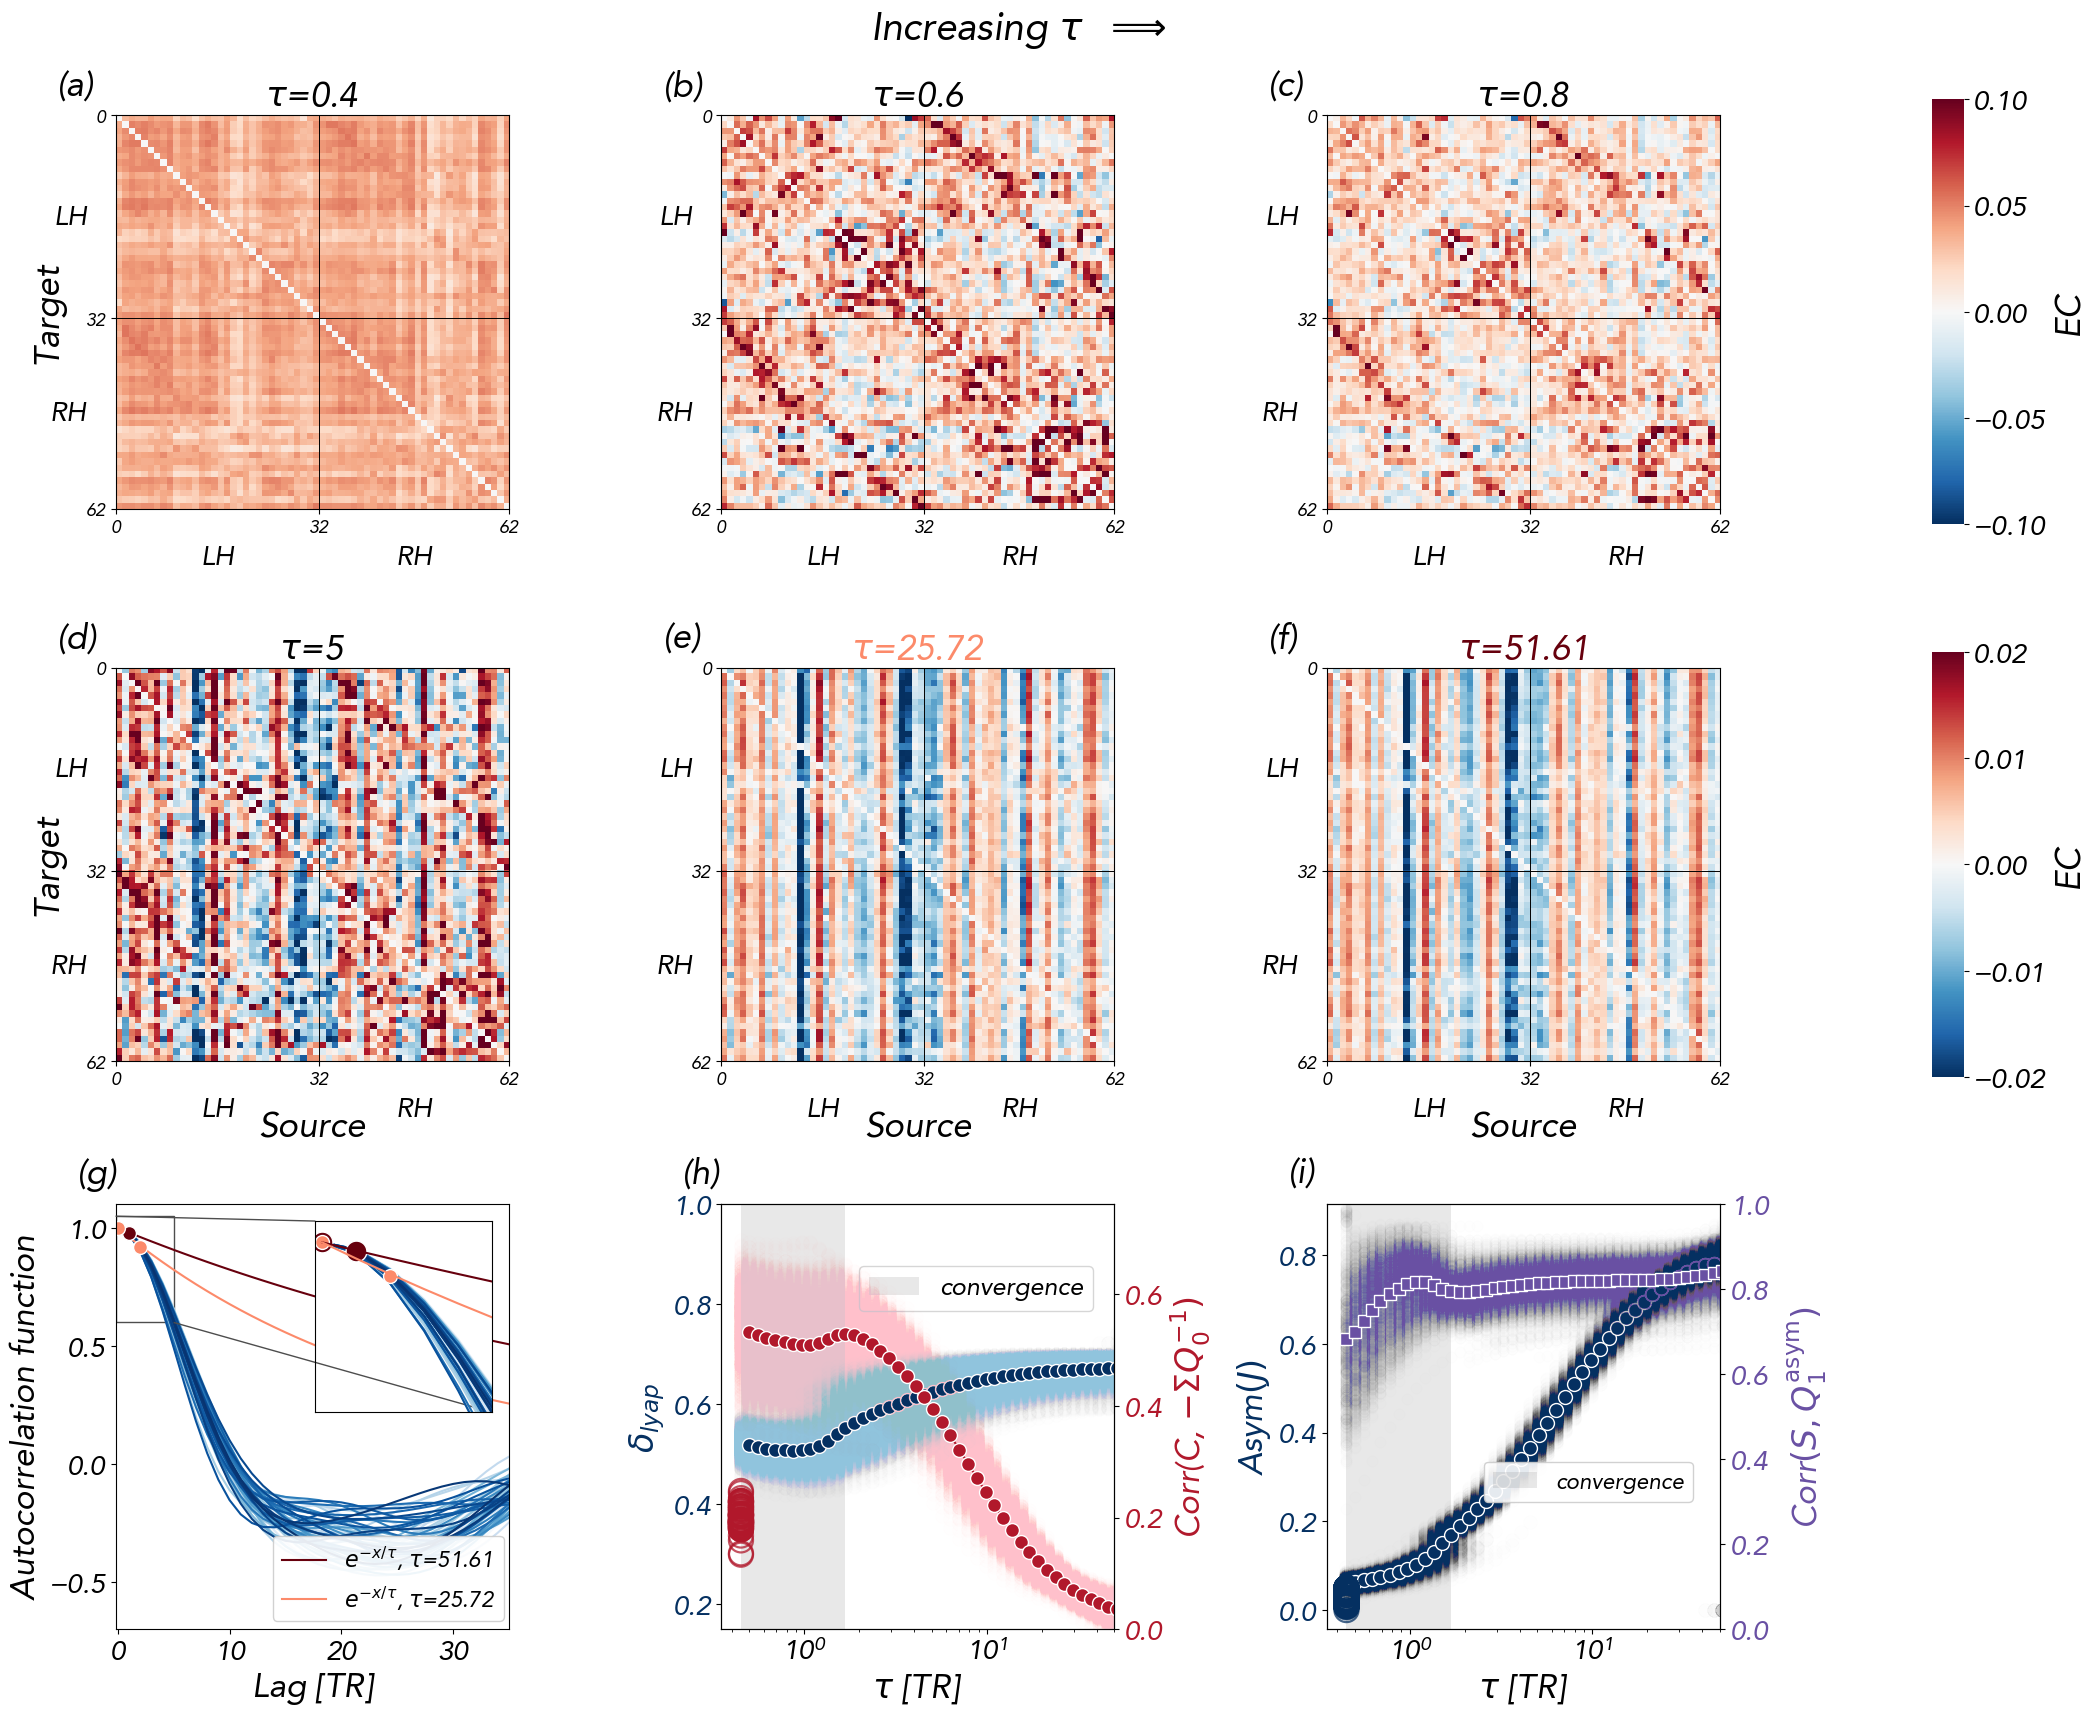

In [59]:
taus = np.logspace(-0.35, 2)
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import cm
import matplotlib.gridspec as gridspec
from mpl_toolkits.axes_grid1.inset_locator import inset_axes, mark_inset
import matplotlib.gridspec as gridspec
from mpl_toolkits.axes_grid1.inset_locator import inset_axes, mark_inset
from collections import OrderedDict
alpha = 0.005
vmin = min((np.percentile(js[i], 2) for i in range(6)))
vmax = max((np.percentile(js[i], 98) for i in range(6)))
plt.rcParams['font.size'] = 24
fontsize = 25
cmap_div = cm.RdBu_r
cmap_blue = cm.Blues
colors = [cmap_div(i / 10) for i in range(10)]
kk = cm.Reds(np.linspace(0, 1, 6))
asym_color = colors[0]
directionality_color = cm.Purples(0.75)
q0_threshold = 0.7
precision_threshold = 0.25
asymmetry_threshold = 0.05
delta_threshold = 0.05
highlight_size = 300
highlight_linewidth = 1.6
highlight_alpha = 0.75

def get_sweet_spot(taus, correlation, fraction_of_peak=0.87):
    taus = np.asarray(taus, dtype=float)
    correlation = np.asarray(correlation, dtype=float)
    valid = np.isfinite(taus) & np.isfinite(correlation)
    taus_valid = taus[valid]
    corr_valid = correlation[valid]
    if len(taus_valid) == 0:
        return (np.nan, np.nan)
    peak_index = np.nanargmax(corr_valid)
    peak_value = corr_valid[peak_index]
    threshold = fraction_of_peak * peak_value
    high_mask = corr_valid >= threshold
    left_index = peak_index
    while left_index > 0 and high_mask[left_index - 1]:
        left_index -= 1
    right_index = peak_index
    while right_index < len(corr_valid) - 1 and high_mask[right_index + 1]:
        right_index += 1
    return (taus_valid[left_index], taus_valid[right_index])
corr100 = np.asarray(corr100, dtype=float)
corr100_ = np.asarray(corr100_, dtype=float)
ass100 = np.asarray(ass100, dtype=float)
corr_S_Q1asym = np.asarray(corr_S_Q1asym, dtype=float)
from collections import Counter
mapping_100_to_62 = np.array([1, 2, 2, 2, 2, 2, 2, 2, 2, 3, 3, 3, 4, 5, 5, 6, 7, 8, 7, 8, 7, 9, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 24, 25, 24, 26, 27, 28, 29, 28, 30, 31, 32, 32, 33, 34, 34, 34, 35, 35, 34, 35, 36, 36, 36, 37, 38, 38, 38, 38, 39, 40, 41, 41, 42, 43, 43, 44, 45, 46, 47, 47, 48, 49, 50, 51, 52, 52, 53, 52, 54, 55, 54, 56, 57, 58, 58, 59, 59, 60, 60, 61, 62, 62])
print('Mapping:', mapping_100_to_62.shape, 'range =', mapping_100_to_62.min(), '-', mapping_100_to_62.max())

def aggregate_fc(fc_100, mapping=mapping_100_to_62):
    fc_62 = np.full((62, 62), np.nan)
    for i in range(1, 63):
        ii = np.where(mapping == i)[0]
        for j in range(1, 63):
            jj = np.where(mapping == j)[0]
            fc_62[i - 1, j - 1] = np.nanmean(fc_100[np.ix_(ii, jj)])
    return fc_62

def aggregate_labels(labels_100, mapping=mapping_100_to_62):
    labels_100 = np.asarray(labels_100)
    labels_62 = []
    for k in range(1, 63):
        idx = np.where(mapping == k)[0]
        labs = labels_100[idx]
        hemis = [str(x).split('_')[0] for x in labs]
        nets = [str(x).split('_')[1] for x in labs]
        hemi = Counter(hemis).most_common(1)[0][0]
        net = Counter(nets).most_common(1)[0][0]
        labels_62.append(f'{hemi}_{net}_{k}')
    return np.array(labels_62)

def plot_fc_matrix(fc, labels, ax, cmap='bwr', vmin=-0.2, vmax=0.2, fontsize=13, pos=7, plot_networks=False, plot_emi_x=True, plot_emi_y=True):
    fc = np.asarray(fc)
    labels = np.asarray(labels)
    if fc.ndim != 2 or fc.shape[0] != fc.shape[1]:
        raise ValueError('La matrice deve essere quadrata.')
    if labels.ndim != 1 or len(labels) != fc.shape[0] or len(labels) == 0:
        raise ValueError('Serve una etichetta per ogni regione.')
    if any(len(str(lab).split('_')) < 2 or str(lab).split('_')[0] not in ('LH', 'RH') for lab in labels):
        raise ValueError('Etichette attese: LH_rete_regione oppure RH_rete_regione.')

    def parse_label(lab):
        p = str(lab).split('_')
        return (p[0], p[1])
    groups = OrderedDict()
    for (i, lab) in enumerate(labels):
        (hemi, net) = parse_label(lab)
        groups.setdefault(f'{hemi}_{net}', []).append(i)
    new_order = []
    bounds = []
    names = []
    start = 0
    ordered_keys = [key for hemi in ('LH', 'RH') for key in groups if key.startswith(hemi + '_')]
    for key in ordered_keys:
        idxs = groups[key]
        new_order.extend(idxs)
        end = start + len(idxs)
        bounds.append((start, end))
        names.append(key)
        start = end
    fc_ord = fc[np.ix_(new_order, new_order)]
    labels_ord = labels[new_order]
    n = len(labels_ord)
    im = ax.imshow(fc_ord, cmap=cmap, vmin=vmin, vmax=vmax, interpolation='none', origin='upper')
    if plot_networks:
        for (start, end) in bounds:
            ax.axhline(end - 0.5, color='black', lw=0.2)
            ax.axvline(end - 0.5, color='black', lw=0.2)
        for ((start, end), name) in zip(bounds, names):
            center = (start + end) / 2 - 0.5
            net = name.split('_', 1)[1]
            ax.text(center, n + 1, net, ha='center', va='top', rotation=70, fontsize=fontsize, clip_on=False)
            ax.text(-1, center, net, ha='right', va='center', fontsize=fontsize, clip_on=False)
    lh_count = np.sum([str(x).startswith('LH_') for x in labels_ord])
    if 0 < lh_count < n:
        ax.axhline(lh_count - 0.5, color='black', lw=0.7)
        ax.axvline(lh_count - 0.5, color='black', lw=0.7)
    lh_center = lh_count / 2 - 0.5
    rh_center = lh_count + (n - lh_count) / 2 - 0.5
    if plot_emi_x:
        ax.text(lh_center, n + 1 + pos, 'LH', ha='center', va='top', fontsize=20, fontweight='bold', clip_on=False)
        ax.text(rh_center, n + 1 + pos, 'RH', ha='center', va='top', fontsize=20, fontweight='bold', clip_on=False)
    if plot_emi_y:
        ax.text(-1 - pos, lh_center, 'LH', ha='right', va='center', fontsize=20, fontweight='bold', clip_on=False)
        ax.text(-1 - pos, rh_center, 'RH', ha='right', va='center', fontsize=20, fontweight='bold', clip_on=False)
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_xlim(-0.5, n - 0.5)
    ax.set_ylim(n - 0.5, -0.5)
    return im
labels_62 = aggregate_labels(labels100)
vmin = min([np.percentile(js[i], 2) for i in range(6)])
vmax = max([np.percentile(js[i], 98) for i in range(6)])
fontsize = 25
cmap_div = cm.RdBu_r
cmap_blue = cm.Blues
colors = [cmap_div(i / 10) for i in range(10)]
kk = cm.Reds(np.linspace(0, 1, 6))
fig = plt.figure(figsize=(21, 18), constrained_layout=False)
fig.suptitle('Increasing $\\tau$  $\\Longrightarrow$', fontsize=28, fontweight='bold', y=0.98)
gs = gridspec.GridSpec(3, 4, height_ratios=[1, 1, 1], width_ratios=[1, 1, 1, 0.08], hspace=0.3, wspace=0.7)
panel_labels = ['(a)', '(b)', '(c)', '(d)', '(e)', '(f)']
taus = [0.4, 0.6, 0.8, 5, round(tau_obj_, 2), round(tau_obj, 2)]
axes_mat = []
ims = []
for i in range(6):
    ax = fig.add_subplot(gs[i // 3, i % 3])
    axes_mat.append(ax)
    ax.text(-0.15, 1.05, panel_labels[i], transform=ax.transAxes, fontsize=fontsize, fontweight='bold')
    if i % 3 == 0:
        ax.set_ylabel('Target', fontsize=fontsize, labelpad=15)
    if i // 3 == 1:
        ax.set_xlabel('Source', fontsize=fontsize, labelpad=15)
    vmaxss = [0.1, 0.1, 0.1, 0.02, 0.02, 0.02]
    im = plot_fc_matrix(dediag(js[i]).T, labels_62, ax, 'RdBu_r', -vmaxss[i], vmaxss[i], plot_networks=False, pos=4)
    ims.append(im)
    n_regions = len(labels_62)
    n_left = sum(str(label).startswith('LH_') for label in labels_62)
    boundaries = np.unique([0, n_left, n_regions])
    ax.set_xticks(boundaries - 0.5)
    ax.set_yticks(boundaries - 0.5)
    ax.set_xticklabels(boundaries, fontsize=13)
    ax.set_yticklabels(boundaries, fontsize=13)
    if i not in [4, 5]:
        ax.set_title('$\\tau$=' + f'{taus[i]}', fontsize=fontsize, fontweight='bold')
    elif i == 4:
        ax.set_title('$\\tau$=' + f'{taus[i]}', fontsize=fontsize, fontweight='bold', color=kk[2])
    elif i == 5:
        ax.set_title('$\\tau$=' + f'{taus[i]}', fontsize=fontsize, fontweight='bold', color=kk[5])
cax = fig.add_subplot(gs[:1, 3])
cbar = fig.colorbar(ims[0], cax=cax)
cbar.set_label('EC', fontsize=fontsize)
cbar.outline.set_visible(False)
cax = fig.add_subplot(gs[1:2, 3])
cbar = fig.colorbar(ims[4], cax=cax)
cbar.set_label('EC', fontsize=fontsize)
cbar.outline.set_visible(False)
ax0 = fig.add_subplot(gs[2, 0])
num_series = cc.shape[0]
x = np.arange(cc.shape[1])
for i in range(num_series):
    ax0.plot(x, cc[i, :], color=cmap_blue(i / num_series))
ax0.plot(x, np.exp(-x / tau_obj), color=kk[5], label='$e^{-x/\\tau}$, $\\tau$=' + f'{round(tau_obj, 2)}')
ax0.plot(x, np.exp(-x / tau_obj_), color=kk[2], label='$e^{-x/\\tau}$, $\\tau$=' + f'{round(tau_obj_, 2)}')
ax0.plot([x[0], x[1]], [cc[10, 0], cc[10, 1]], 'o', color=kk[5], markersize=10, markeredgecolor='white')
ax0.plot([x[0], x[2]], [cc[10, 0], cc[10, 2]], 'o', color=kk[2], markersize=10, markeredgecolor='white')
ax0.set_xlim(-0.2, 35)
ax0.set_ylim(-0.7, 1.1)
ax0.set_xlabel('Lag [TR]')
ax0.set_ylabel('Autocorrelation function')
ax0.text(-0.1, 1.05, '(g)', transform=ax0.transAxes, fontsize=fontsize, fontweight='bold')
ax0.legend(fontsize=16, loc=(0.4, 0.02), framealpha=0.9)
axins = inset_axes(ax0, width='45%', height='45%', loc='upper right')
for i in range(num_series):
    axins.plot(x, cc[i, :], color=cmap_blue(i / num_series))
axins.plot([x[0], x[1]], [cc[10, 0], cc[10, 1]], 'o', color=kk[5], markersize=15, markeredgecolor='white')
axins.plot([x[0], x[2]], [cc[10, 0], cc[10, 2]], 'o', color=kk[2], markersize=10, markeredgecolor='white')
axins.plot(x, np.exp(-x / tau_obj), color=kk[5])
axins.plot(x, np.exp(-x / tau_obj_), color=kk[2])
axins.set_xlim(-0.2, 5)
axins.set_ylim(0.6, 1.05)
axins.set_xticks([])
axins.set_yticks([])
mark_inset(ax0, axins, loc1=2, loc2=4, fc='none', ec='0.3')
taus = np.round(np.logspace(-0.35, 2), 2)
taus = np.round(np.logspace(-0.35, 2, corr100_.shape[1]), 2)
if len(taus) != corr_S_Q1asym.shape[1]:
    raise ValueError('corr_S_Q1asym must have one column for each tau value.')
mean_corr_q0 = np.nanmean(my_info_ec, axis=0)
mean_corr_precision = np.nanmean(corr100, axis=0)
mean_asymmetry = np.nanmean(ass100, axis=0)
mean_directionality = np.nanmean(corr_S_Q1asym, axis=0)
(sweet_tau_left, sweet_tau_right) = get_sweet_spot(taus[1:], np.mean(corr_, 0)[1:], fraction_of_peak=0.9)
print('Automatic sweet spot:', sweet_tau_left, sweet_tau_right)
sweet_tau_left = 0.45
print('Plotted sweet spot:', sweet_tau_left, sweet_tau_right)
first_q0_values = my_info_ec[:, 0]
first_precision_values = corr100[:, 0]
first_asymmetry_values = ass100[:, 0]
first_delta_values = my_info_ec[:, 0]
mask_q0_first = np.isfinite(first_q0_values) & (first_q0_values > q0_threshold)
mask_precision_first = np.isfinite(first_precision_values) & (first_precision_values < precision_threshold)
mask_asymmetry_first = np.isfinite(first_asymmetry_values) & (first_asymmetry_values < asymmetry_threshold)
mask_delta_first = np.isfinite(first_delta_values) & (first_delta_values < delta_threshold)
ax2 = fig.add_subplot(gs[2, 1])
ax2.plot(taus, my_info_ec.T, 'o', markersize=10, color=colors[3], alpha=alpha)
ax2.plot(taus[1:], mean_corr_q0[1:], '-o', ms=10, color=colors[0], markeredgecolor='white')
axx = ax2.twinx()
print(taus[0])
axx.plot(taus, corr100.T, 'o', markersize=10, color='pink', alpha=alpha)
axx.scatter(np.full(np.sum(mask_precision_first), taus[0]), first_precision_values[mask_precision_first], s=highlight_size, facecolors='none', edgecolors=colors[9], linewidths=highlight_linewidth, alpha=highlight_alpha, zorder=6)
axx.plot(taus[1:], mean_corr_precision[1:], '-o', ms=10, color=colors[9], markeredgecolor='white')
ax2.axvspan(sweet_tau_left, sweet_tau_right, color='grey', alpha=0.18, linewidth=0, label='convergence')
ax2.set_xlabel('$\\tau$ [TR]')
ax2.set_ylabel('$\\delta_{lyap}$', color=colors[0])
axx.set_ylabel('Corr(C, $-\\Sigma Q_0^{-1})$', color=colors[9])
ax2.tick_params(axis='y', labelcolor=colors[0])
axx.tick_params(axis='y', labelcolor=colors[9])
ax2.set_ylim(0.15, 1)
axx.set_ylim(0, 0.76)
ax2.set_xlim(0.35, 50)
ax2.set_xscale('log')
axx.set_xlim(0.35, 50)
axx.set_xscale('log')
ax2.text(-0.1, 1.05, '(h)', transform=ax2.transAxes, fontsize=fontsize, fontweight='bold')
ax2.legend(loc=(0.35, 0.75), fontsize=18)
ax1 = fig.add_subplot(gs[2, 2])
ax1.plot(taus[:], ass[:, :].T, 'o', color=asym_color, alpha=alpha, markersize=10)
ax1.scatter(np.full(np.sum(mask_asymmetry_first), taus[0]), first_asymmetry_values[mask_asymmetry_first], s=highlight_size, facecolors='none', edgecolors=asym_color, linewidths=highlight_linewidth, alpha=highlight_alpha, zorder=6)
asym_line = ax1.plot(taus[1:], np.mean(ass[:, 1:], 0), '-o', ms=10, linewidth=2, color=asym_color, markeredgecolor='white')[0]
sweet_patch = ax1.axvspan(sweet_tau_left, sweet_tau_right, color='grey', alpha=0.18, linewidth=0, label='convergence')
ax1.set_xscale('log')
ax1.set_xlim(0.35, 50)
ax1.set_xlabel('$\\tau$ [TR]')
ax1.set_ylabel('Asym$(J)$', color=asym_color)
ax1.tick_params(axis='y', labelcolor=asym_color)
ax1.text(-0.1, 1.05, '(i)', transform=ax1.transAxes, fontsize=fontsize, fontweight='bold')
ax1_dir = ax1.twinx()
ax1_dir.plot(taus, corr_S_Q1asym.T, 'o', color=directionality_color, alpha=alpha, markersize=8)
directionality_line = ax1_dir.plot(taus, mean_directionality, '-s', ms=8, linewidth=2, color=directionality_color, markeredgecolor='white')[0]
ax1_dir.set_ylabel('Corr$(S,Q_{1}^{\\mathrm{asym}})$', color=directionality_color, labelpad=12)
ax1_dir.tick_params(axis='y', labelcolor=directionality_color)
ax1_dir.set_ylim(0.0, 1.0)
ax1.legend(handles=[sweet_patch], labels=['convergence'], fontsize=16, loc=(0.4, 0.3), framealpha=0.9)
plt.subplots_adjust(top=0.93, bottom=0.08, left=0.07, right=0.95)
fig.savefig(FIGURES / 'figure_1.jpg', dpi=300, bbox_inches='tight')
plt.show()

np.float64(0.45)

## Soggetti a convergenza

In [18]:
#taus = np.logspace(-0.35, 2)
import numpy as np
taus = np.logspace(-0.35, 2)
taus[0]

np.float64(0.44668359215096315)

1.2296907844759382
10
78.38104639684107


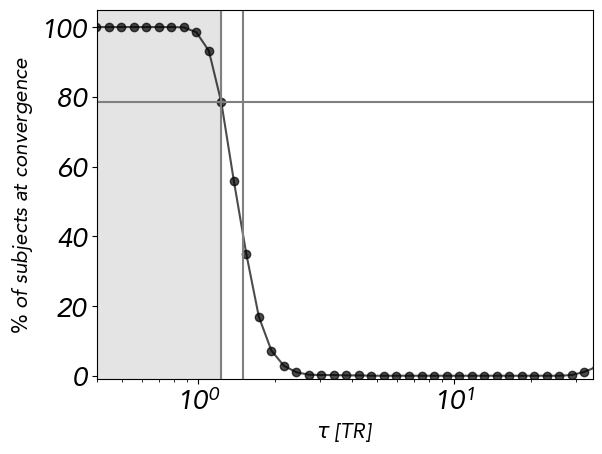

In [26]:
converged = np.load(NUMPY / 'converged.npy')
assert converged.shape == (1013, 50)
plt.figure()
plt.rcParams['font.size'] = 22
taus = np.logspace(-0.4, 2)
plt.plot(taus, np.sum(converged, 0) / 1013 * 100, 'o-', color='black', alpha=0.7)
plt.xscale('log')
plt.xlim(0.4, 35)
tau_soglia = taus[np.where(np.sum(converged[:, :20], 0) / 1013 * 100 >= 70)[0][-1]]
print(tau_soglia)
index = np.where(np.sum(converged[:, :20], 0) / 1013 * 100 >= 70)[0][-1]
print(index)
val_y = np.sum(converged, 0)[index] / 1013 * 100
plt.vlines(tau_soglia, -1, 110, color='gray')
plt.vlines(1.5, -1, 110, color='gray')

plt.hlines(val_y, 0, 1013, color='gray')
print(val_y)
plt.ylabel('$\\%$ of subjects at convergence', fontsize=15)
plt.axvspan(0.4, tau_soglia, color='lightgray', alpha=0.6)
plt.xlabel('$\\tau$ [TR]', fontsize=15)
plt.ylim(-1, 105)
plt.savefig(FIGURES / 'subject_converged.jpg', dpi=300, bbox_inches='tight')
plt.show()